# 04 — Size-matched random tiles (H3K27ac)

On the 2,635 non-plasma B cells with H3K27ac, draw size-matched tile sets of
the **promoter** count (31,143 tiles):

- promoters (full set, embedded once)
- random enhancers (Stephanie MER overlap; **20** repeats)
- random genomic tiles (**20** repeats)

Each draw: spectral → Harmony → Leiden 0.1–1.0 → ARI / NMI / H(label|cluster)
vs the three stages **Naive**, **GC**, and **Memory**. Curves show mean ± min–max
band (promoters in blue; enhancers in green with a light-green band).

Plots are display-only.


In [1]:
%matplotlib inline
import logging
import os
import sys
import time
import warnings
from pathlib import Path

warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", UserWarning)
os.environ["TQDM_DISABLE"] = "1"

import hdf5plugin

os.environ["HDF5_PLUGIN_PATH"] = hdf5plugin.PLUGIN_PATH
os.environ["PATH"] = str(Path(sys.executable).resolve().parent) + os.pathsep + os.environ.get("PATH", "")

import anndata as ad
import matplotlib.pyplot as plt
import muon as mu
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import snapatac2 as snap
from pybedtools import BedTool
from scipy import sparse
from scipy.sparse.linalg import ArpackError
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

PACKAGE = Path("/mnt/data1/divyanshu/treseq/tonsils/codes/treseq_paper")
if str(PACKAGE.parent) not in sys.path:
    sys.path.insert(0, str(PACKAGE.parent))

from treseq_paper import config

sns.set_theme("talk", style="ticks")
sc.settings.verbosity = 1
plt.rcParams["figure.dpi"] = 120
logging.getLogger("harmonypy").setLevel(logging.ERROR)

BCELLS = config.BCELLS
STEPHANIE = config.STEPHANIE_MERS
PROMOTERS_BED = config.PROMOTERS_BED
CHROM_SIZES = config.CHROM_SIZES
LABEL = config.CELLTYPE_KEY
CELLTYPE_SOURCE = config.CELLTYPE_SOURCE_KEY
STAGE_ORDER = config.STAGE_ORDER
RESOLUTIONS = config.BCELL_RESOLUTIONS
N_COMPS = config.N_COMPS
N_NEIGHBORS = config.N_NEIGHBORS
MIN_DIST = config.MIN_DIST
RANDOM_STATE = config.BCELL_RANDOM_STATE
N_MATCHED_REPEATS = config.N_MATCHED_REPEATS
STORED_UP = config.STORED_PROMOTER_UPSTREAM
STORED_DOWN = config.STORED_PROMOTER_DOWNSTREAM
PROMOTER_UPSTREAM = config.PROMOTER_UPSTREAM
PROMOTER_DOWNSTREAM = config.PROMOTER_DOWNSTREAM

def ensure_celltype(obs):
    if LABEL in obs.columns:
        return obs
    if CELLTYPE_SOURCE not in obs.columns:
        raise KeyError(f"missing {LABEL} / {CELLTYPE_SOURCE}")
    return obs.rename(columns={CELLTYPE_SOURCE: LABEL})


def ensure_stage(obs):
    """Map stored preGC/postGC stage labels to Naive/Memory."""
    if "stage" not in obs.columns:
        return obs
    out = obs.copy()
    mapped = out["stage"].astype(str).replace(config.STAGE_SOURCE_MAP)
    unknown = sorted(set(mapped) - set(config.STAGE_ORDER))
    if unknown:
        raise RuntimeError(f"unexpected stage labels: {unknown}")
    out["stage"] = pd.Categorical(mapped, categories=config.STAGE_ORDER)
    return out


# Curve colors: blue promoters; green enhancers (light-green min–max band).
matched_colors = {
    "promoters": "#4C78A8",
    "enhancers": "#54A24B",
    "random tiles": "#333333",
}
matched_sets = ["promoters", "enhancers", "random tiles"]
direction = {"ARI": "higher", "NMI": "higher", "H_label_given_cluster": "lower"}

for path in (BCELLS, STEPHANIE, PROMOTERS_BED, CHROM_SIZES):
    if not path.is_file():
        raise FileNotFoundError(path)


## Helpers


In [2]:
def bin_table(var_names):
    names = pd.Index(var_names).astype(str)
    span = names.str.split(":", n=1).str[1].str.split("-", n=1)
    return pd.DataFrame(
        {
            "chrom": names.str.split(":", n=1).str[0].to_numpy(),
            "start": span.str[0].astype(int).to_numpy(),
            "end": span.str[1].astype(int).to_numpy(),
        }
    )


def promoter_bed(upstream, downstream):
    bed = pd.read_csv(
        PROMOTERS_BED,
        sep="\t",
        header=None,
        names=["chrom", "start", "end", "name", "score", "strand"],
    )
    width = STORED_UP + STORED_DOWN
    if not np.all((bed["end"] - bed["start"]).to_numpy() == width):
        raise RuntimeError(f"Promoter annotation intervals are not all {width} bp")
    plus = bed["strand"].eq("+").to_numpy()
    tss = np.where(plus, bed["start"] + STORED_UP, bed["end"] - STORED_UP)
    start = np.where(plus, tss - upstream, tss - downstream).astype(int)
    end = np.where(plus, tss + downstream, tss + upstream).astype(int)
    sizes = pd.read_csv(CHROM_SIZES, sep="\t", header=None, names=["chrom", "size"])
    size_of = dict(zip(sizes["chrom"], sizes["size"].astype(int)))
    chrom_size = bed["chrom"].map(size_of).to_numpy()
    start = np.clip(start, 0, chrom_size)
    end = np.clip(end, 0, chrom_size)
    out = pd.DataFrame(
        {
            "chrom": bed["chrom"].to_numpy(),
            "start": start,
            "end": end,
            "name": bed["name"].to_numpy(),
            "strand": bed["strand"].to_numpy(),
        }
    )
    return out


def overlap_mask(var_names, bed):
    regions = bin_table(var_names)
    regions["name"] = np.arange(len(regions))
    bins = BedTool.from_dataframe(regions[["chrom", "start", "end", "name"]]).sort()
    other = BedTool.from_dataframe(bed[["chrom", "start", "end"]]).sort()
    hit = bins.intersect(other, u=True).to_dataframe(
        disable_auto_names=True, names=["chrom", "start", "end", "name"]
    )
    mask = np.zeros(len(regions), dtype=bool)
    if len(hit):
        mask[hit["name"].astype(int).to_numpy()] = True
    return mask


def shannon(labels):
    values = pd.Series(np.asarray(labels).astype(str)).value_counts(normalize=True).to_numpy()
    return float(-np.sum(values * np.log2(values)))


def conditional_entropy(labels, clusters):
    labels = np.asarray(labels).astype(str)
    clusters = np.asarray(clusters).astype(str)
    joint = pd.crosstab(pd.Series(clusters), pd.Series(labels))
    probability = joint.to_numpy(dtype=np.float64)
    probability /= probability.sum()
    cluster_probability = probability.sum(axis=1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(probability > 0, probability / cluster_probability, 1.0)
    return float(-np.sum(probability * np.log2(ratio)))


def fit_graph(adata, rep):
    n_neighbors = min(N_NEIGHBORS, adata.n_obs - 1)
    sc.pp.neighbors(
        adata,
        use_rep=rep,
        n_neighbors=n_neighbors,
        metric="euclidean",
        random_state=RANDOM_STATE,
    )
    sc.tl.umap(adata, min_dist=MIN_DIST, spread=1.0, random_state=RANDOM_STATE)
    adata.uns["umap_rep"] = rep


def batch_correct(adata):
    import harmonypy

    corrected = np.asarray(
        harmonypy.run_harmony(
            np.asarray(adata.obsm["X_spectral"], dtype=np.float64),
            adata.obs,
            "sample",
            random_state=RANDOM_STATE,
        ).Z_corr
    )
    if corrected.ndim != 2 or corrected.shape[0] != adata.n_obs:
        corrected = corrected.T
    adata.obsm["X_spectral_harmony"] = corrected.astype(np.float32)


def spectral_embed(adata):
    n_comps = min(N_COMPS, adata.n_obs - 1, adata.n_vars - 1)
    counts = sparse.csr_matrix(adata.X).copy()
    spectral_error = None
    for attempt in range(5):
        adata.obsm.pop("X_spectral", None)
        adata.X = counts.copy()
        try:
            snap.tl.spectral(
                adata,
                n_comps=n_comps,
                features=None,
                random_state=RANDOM_STATE + attempt,
                distance_metric="cosine",
            )
            break
        except ArpackError as exc:
            spectral_error = exc
            print(f"  spectral attempt {attempt + 1} did not converge", flush=True)
    else:
        raise RuntimeError("spectral embedding failed after 5 starts") from spectral_error
    adata.X = counts
    adata.obsm["X_spectral"] = np.asarray(adata.obsm["X_spectral"], dtype=np.float32)


def embed_histone(adata):
    spectral_embed(adata)
    batch_correct(adata)
    fit_graph(adata, "X_spectral_harmony")
    adata.uns["n_bins"] = int(adata.n_vars)
    adata.uns["n_comps"] = int(adata.obsm["X_spectral"].shape[1])
    return adata


def tile_subset(counts, obs, var_names, keep):
    columns = np.flatnonzero(keep)
    matrix = counts[:, columns]
    matrix = matrix.tocsr().copy() if sparse.issparse(matrix) else sparse.csr_matrix(matrix)
    return ad.AnnData(
        X=matrix,
        obs=obs.copy(),
        var=pd.DataFrame(index=pd.Index(var_names[columns].astype(str), name="tile")),
    )


def nonzero_columns(X, mask):
    counts = np.asarray(X.sum(axis=0)).ravel()
    keep = mask & (counts > 0)
    if int(keep.sum()) < 2:
        raise RuntimeError("Fewer than 2 tiles with a count")
    return keep


def keep_from_pool(pool, n_draw, n_vars, rng):
    chosen = pool if len(pool) == n_draw else rng.choice(pool, size=n_draw, replace=False)
    keep = np.zeros(n_vars, dtype=bool)
    keep[np.asarray(chosen, dtype=int)] = True
    return keep


## Run 20× matched draws


In [3]:
mdata = mu.read_h5mu(BCELLS)
source = mdata.mod["H3K27ac"]
if source.n_obs != 2635:
    raise RuntimeError(f"H3K27ac has {source.n_obs} cells, expected 2635")
data = ad.AnnData(
    X=sparse.csr_matrix(source.X).copy(),
    obs=ensure_stage(ensure_celltype(source.obs))[[LABEL, "sample", "stage"]].copy(),
    var=pd.DataFrame(index=pd.Index(source.var_names.astype(str), name="tile")),
)
print(f"H3K27ac: {data.n_obs} cells x {data.n_vars:,} tiles")
del mdata, source

promoters = promoter_bed(PROMOTER_UPSTREAM, PROMOTER_DOWNSTREAM)
enhancers = pd.read_csv(
    STEPHANIE, sep="\t", header=None, usecols=[0, 1, 2], names=["chrom", "start", "end"]
)
promoter_mask = overlap_mask(data.var_names, promoters)
enhancer_mask = overlap_mask(data.var_names, enhancers)
detected = {
    "promoters": nonzero_columns(data.X, promoter_mask),
    "enhancers": nonzero_columns(data.X, enhancer_mask),
    "random tiles": nonzero_columns(data.X, np.ones(data.n_vars, dtype=bool)),
}
print(
    f"detected tiles: promoters {int(detected['promoters'].sum()):,}, "
    f"enhancers {int(detected['enhancers'].sum()):,}, "
    f"all {int(detected['random tiles'].sum()):,}"
)

partitions = {
    "stage": (data.obs["stage"].astype(str).to_numpy(), STAGE_ORDER),
}

pools = {name: np.flatnonzero(mask) for name, mask in detected.items()}
n_match = int(len(pools["promoters"]))
if len(pools["enhancers"]) < n_match or len(pools["random tiles"]) < n_match or n_match < 2:
    raise RuntimeError(f"cannot draw {n_match} tiles from each pool")
print(f"every draw uses {n_match:,} tiles (promoter count); promoters embedded once")

matched_score_rows = []
draw_rng = np.random.default_rng(RANDOM_STATE)


def score_matched_draw(set_name, repeat, keep):
    if int(keep.sum()) != n_match:
        raise RuntimeError(f"{set_name} draw {repeat} has {int(keep.sum())} tiles, not {n_match}")
    view = embed_histone(tile_subset(data.X, data.obs, data.var_names, keep))
    for resolution in RESOLUTIONS:
        sc.tl.leiden(view, resolution=float(resolution), key_added="leiden", random_state=RANDOM_STATE)
        clusters = view.obs["leiden"].astype(str).to_numpy()
        n_clusters = int(pd.unique(clusters).size)
        for partition, (labels, _) in partitions.items():
            matched_score_rows.append(
                {
                    "set": set_name,
                    "repeat": repeat,
                    "partition": partition,
                    "resolution": float(resolution),
                    "n_bins": int(view.uns["n_bins"]),
                    "n_clusters": n_clusters,
                    "ARI": adjusted_rand_score(labels, clusters),
                    "NMI": normalized_mutual_info_score(labels, clusters),
                    "H_label_given_cluster": conditional_entropy(labels, clusters),
                    "H_label": shannon(labels),
                }
            )
    del view


started = time.time()
for set_name in matched_sets:
    n_repeats = 1 if set_name == "promoters" else N_MATCHED_REPEATS
    for repeat in range(n_repeats):
        one = time.time()
        embedded = False
        attempts = 1 if n_repeats == 1 else 8
        for _attempt in range(attempts):
            try:
                score_matched_draw(
                    set_name,
                    repeat,
                    keep_from_pool(pools[set_name], n_match, data.n_vars, draw_rng),
                )
                embedded = True
                break
            except RuntimeError as exc:
                if n_repeats == 1 or "spectral embedding failed" not in str(exc):
                    raise
                print(f"  {set_name} {repeat + 1} spectral did not converge, redrawing", flush=True)
        if not embedded:
            raise RuntimeError(f"{set_name} repeat {repeat + 1} had no embeddable tile set")
        if n_repeats == 1:
            print(f"  {set_name} embedded in {time.time() - one:.0f}s", flush=True)
        else:
            print(f"  {set_name} {repeat + 1}/{n_repeats} in {time.time() - one:.0f}s", flush=True)
print(f"size-matched test done in {time.time() - started:.0f}s", flush=True)

matched_scores = pd.DataFrame(matched_score_rows)
matched_scores.insert(0, "modality", "H3K27ac")
if not (matched_scores["n_bins"] == n_match).all():
    raise RuntimeError("a draw did not keep the matched tile count")
display(matched_scores.head())


H3K27ac: 2635 cells x 1,618,834 tiles
detected tiles: promoters 31,143, enhancers 80,459, all 1,618,834
every draw uses 31,143 tiles (promoter count); promoters embedded once


2026-11-13 11:00:50,469 - harmonypy - INFO - Running Harmony
2026-11-13 11:00:50 - INFO - Running Harmony
2026-11-13 11:00:50,471 - harmonypy - INFO -   Parameters:
2026-11-13 11:00:50 - INFO -   Parameters:
2026-11-13 11:00:50,471 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-13 11:00:50 - INFO -     max_iter_harmony: 10
2026-11-13 11:00:50,472 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-13 11:00:50 - INFO -     max_iter_kmeans: 4
2026-11-13 11:00:50,473 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-13 11:00:50 - INFO -     epsilon_cluster: 0.001
2026-11-13 11:00:50,474 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-13 11:00:50 - INFO -     epsilon_harmony: 0.01
2026-11-13 11:00:50,474 - harmonypy - INFO -     nclust: 88
2026-11-13 11:00:50 - INFO -     nclust: 88
2026-11-13 11:00:50,475 - harmonypy - INFO -     block_size: 0.05
2026-11-13 11:00:50 - INFO -     block_size: 0.05
2026-11-13 11:00:50,476 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)

  promoters embedded in 14s


2026-11-13 11:01:03,341 - harmonypy - INFO - Running Harmony
2026-11-13 11:01:03 - INFO - Running Harmony
2026-11-13 11:01:03,342 - harmonypy - INFO -   Parameters:
2026-11-13 11:01:03 - INFO -   Parameters:
2026-11-13 11:01:03,343 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-13 11:01:03 - INFO -     max_iter_harmony: 10
2026-11-13 11:01:03,344 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-13 11:01:03 - INFO -     max_iter_kmeans: 4
2026-11-13 11:01:03,345 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-13 11:01:03 - INFO -     epsilon_cluster: 0.001
2026-11-13 11:01:03,345 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-13 11:01:03 - INFO -     epsilon_harmony: 0.01
2026-11-13 11:01:03,346 - harmonypy - INFO -     nclust: 88
2026-11-13 11:01:03 - INFO -     nclust: 88
2026-11-13 11:01:03,346 - harmonypy - INFO -     block_size: 0.05
2026-11-13 11:01:03 - INFO -     block_size: 0.05
2026-11-13 11:01:03,347 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)

  enhancers 1/20 in 10s


2026-11-13 11:01:13,270 - harmonypy - INFO - Running Harmony
2026-11-13 11:01:13 - INFO - Running Harmony
2026-11-13 11:01:13,271 - harmonypy - INFO -   Parameters:
2026-11-13 11:01:13 - INFO -   Parameters:
2026-11-13 11:01:13,272 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-13 11:01:13 - INFO -     max_iter_harmony: 10
2026-11-13 11:01:13,273 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-13 11:01:13 - INFO -     max_iter_kmeans: 4
2026-11-13 11:01:13,274 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-13 11:01:13 - INFO -     epsilon_cluster: 0.001
2026-11-13 11:01:13,275 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-13 11:01:13 - INFO -     epsilon_harmony: 0.01
2026-11-13 11:01:13,276 - harmonypy - INFO -     nclust: 88
2026-11-13 11:01:13 - INFO -     nclust: 88
2026-11-13 11:01:13,276 - harmonypy - INFO -     block_size: 0.05
2026-11-13 11:01:13 - INFO -     block_size: 0.05
2026-11-13 11:01:13,277 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)

... (74 outputs left out)

  random tiles 19/20 in 9s


2026-11-13 11:06:53,449 - harmonypy - INFO - Running Harmony
2026-11-13 11:06:53 - INFO - Running Harmony
2026-11-13 11:06:53,450 - harmonypy - INFO -   Parameters:
2026-11-13 11:06:53 - INFO -   Parameters:
2026-11-13 11:06:53,451 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-13 11:06:53 - INFO -     max_iter_harmony: 10
2026-11-13 11:06:53,451 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-13 11:06:53 - INFO -     max_iter_kmeans: 4
2026-11-13 11:06:53,452 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-13 11:06:53 - INFO -     epsilon_cluster: 0.001
2026-11-13 11:06:53,452 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-13 11:06:53 - INFO -     epsilon_harmony: 0.01
2026-11-13 11:06:53,453 - harmonypy - INFO -     nclust: 88
2026-11-13 11:06:53 - INFO -     nclust: 88
2026-11-13 11:06:53,453 - harmonypy - INFO -     block_size: 0.05
2026-11-13 11:06:53 - INFO -     block_size: 0.05
2026-11-13 11:06:53,454 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)

  random tiles 20/20 in 8s
size-matched test done in 373s


,modality,set,repeat,partition,resolution,n_bins,n_clusters,ARI,NMI,H_label_given_cluster,H_label
0,H3K27ac,promoters,0,stage,0.1,31143,1,0.000000,0.000000,1.397015,1.397015
1,H3K27ac,promoters,0,stage,0.2,31143,3,-0.002930,0.001143,1.396158,1.397015
2,H3K27ac,promoters,0,stage,0.3,31143,7,-0.002531,0.004945,1.392841,1.397015
3,H3K27ac,promoters,0,stage,0.4,31143,9,0.269479,0.189414,1.138223,1.397015
4,H3K27ac,promoters,0,stage,0.5,31143,13,0.246678,0.189704,1.117675,1.397015


## Summary and curves


,reference,partition,resolution,set,metric,reference_value,mean,min,max,draws_better_than_reference,n_draws
12,promoters,stage,0.3,enhancers,ARI,-0.003,0.433,0.410,0.474,20,20
13,promoters,stage,0.3,enhancers,NMI,0.005,0.332,0.318,0.371,20,20
14,promoters,stage,0.3,enhancers,H_label_given_cluster,1.393,0.997,0.956,1.012,20,20
15,promoters,stage,0.3,random tiles,ARI,-0.003,0.054,0.027,0.085,20,20
16,promoters,stage,0.3,random tiles,NMI,0.005,0.015,0.009,0.021,20,20
17,promoters,stage,0.3,random tiles,H_label_given_cluster,1.393,1.376,1.363,1.387,20,20
24,promoters,stage,0.5,enhancers,ARI,0.247,0.420,0.393,0.444,20,20
25,promoters,stage,0.5,enhancers,NMI,0.190,0.318,0.297,0.338,20,20
26,promoters,stage,0.5,enhancers,H_label_given_cluster,1.118,0.984,0.963,1.008,20,20
27,promoters,stage,0.5,random tiles,ARI,0.247,0.104,0.070,0.145,0,20


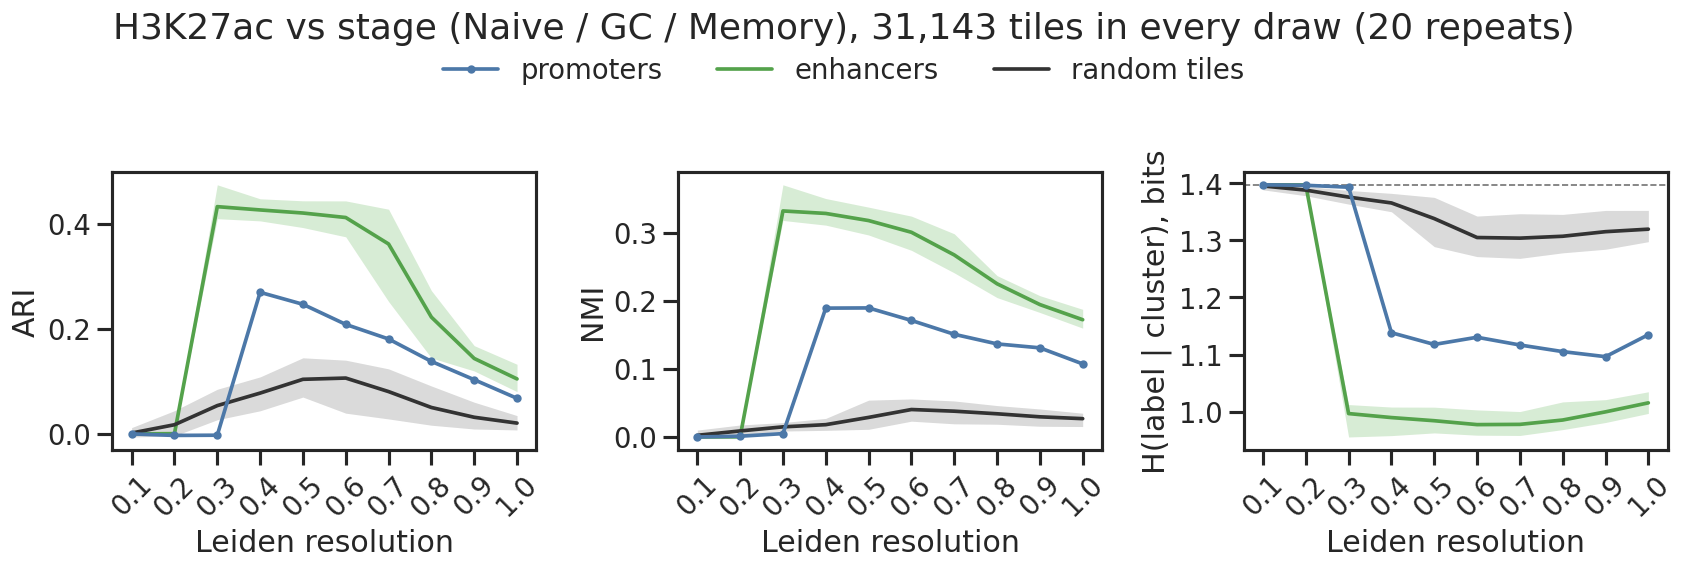

In [4]:
def reference_value(scores, partition, resolution, reference, metric):
    block = scores[
        (scores["partition"] == partition)
        & (scores["resolution"] == resolution)
        & (scores["set"] == reference)
    ]
    values = block[metric].to_numpy(dtype=float)
    if len(values) != 1:
        raise RuntimeError(f"{reference} should be one embedding, found {len(values)}")
    return float(values[0])


def repeat_values(scores, partition, resolution, set_name, metric):
    block = scores[
        (scores["partition"] == partition)
        & (scores["resolution"] == resolution)
        & (scores["set"] == set_name)
    ]
    values = block[metric].to_numpy(dtype=float)
    if len(values) == 0:
        raise RuntimeError(f"{set_name} has no scores")
    return values


summary_rows = []
for partition in ("stage",):
    for resolution in RESOLUTIONS:
        for set_name in ("enhancers", "random tiles"):
            for metric, which in direction.items():
                values = repeat_values(matched_scores, partition, resolution, set_name, metric)
                baseline = reference_value(matched_scores, partition, resolution, "promoters", metric)
                better = values > baseline if which == "higher" else values < baseline
                summary_rows.append(
                    {
                        "reference": "promoters",
                        "partition": partition,
                        "resolution": float(resolution),
                        "set": set_name,
                        "metric": metric,
                        "reference_value": baseline,
                        "mean": float(np.mean(values)),
                        "min": float(np.min(values)),
                        "max": float(np.max(values)),
                        "draws_better_than_reference": int(better.sum()),
                        "n_draws": int(len(values)),
                    }
                )
matched_summary = pd.DataFrame(summary_rows)
shown = matched_summary[matched_summary["resolution"].isin([0.3, 0.5, 1.0])].copy()
for column in ("reference_value", "mean", "min", "max"):
    shown[column] = shown[column].round(3)
display(shown)


def matched_resolution_curves(scores, n_match):
    metrics = [
        ("ARI", "ARI"),
        ("NMI", "NMI"),
        ("H_label_given_cluster", "H(label | cluster), bits"),
    ]
    for partition in ("stage",):
        block = scores[scores["partition"] == partition]
        fig, axes = plt.subplots(1, len(metrics), figsize=(4.8 * len(metrics), 4.3), sharex=True)
        for ax, (metric, ylabel) in zip(axes, metrics):
            for name in matched_sets:
                one = block[block["set"] == name]
                color = matched_colors[name]
                if one["repeat"].nunique() == 1:
                    ax.plot(
                        one["resolution"],
                        one[metric],
                        color=color,
                        marker="o",
                        ms=4,
                        lw=2.2,
                        label=name,
                        zorder=3,
                    )
                else:
                    summary = one.groupby("resolution")[metric].agg(["mean", "min", "max"])
                    ax.plot(summary.index, summary["mean"], color=color, lw=2.2, label=name)
                    band = "#A8D5A2" if name == "enhancers" else color
                    ax.fill_between(
                        summary.index,
                        summary["min"],
                        summary["max"],
                        color=band,
                        alpha=0.45 if name == "enhancers" else 0.18,
                        linewidth=0,
                        zorder=1,
                    )
            if metric == "H_label_given_cluster":
                ceiling = float(block["H_label"].iloc[0])
                ax.axhline(ceiling, color="0.45", ls="--", lw=1, label="H(label)")
            ax.set_xlabel("Leiden resolution")
            ax.set_ylabel(ylabel)
            ax.set_xticks(RESOLUTIONS)
            ax.tick_params(axis="x", labelrotation=45)
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.08))
        fig.suptitle(f"H3K27ac vs stage (Naive / GC / Memory), {n_match:,} tiles in every draw (20 repeats)", y=1.12)
        fig.tight_layout()
        # fig.savefig(...)  # disabled
        plt.show()


matched_resolution_curves(matched_scores, n_match)
